# The scalar ruler: mass scaling and a safe default

`GlobalMesh.anchor_line_mesh_(q, w0, xi_ref)` converts a line's
dimensionless template to wavelengths with one scalar reference velocity:
$\lambda = \lambda_0 (1 + q\,\xi_{\rm ref}/c)$. RH does exactly this —
`getlambda.c` uses `q_to_lambda = lambda0 * (vmicro_char / CLIGHT)` with a
single **species-independent** `VMICRO_CHAR`, pushing any mass dependence
into hand-tuned per-line `qcore`/`qwing` in the atom files. This notebook
measures three questions instead of inheriting that convention:

1. **Where does the characteristic width come from?** The physical scale of
   a line is its Doppler width $v_D = \sqrt{2kT/m + \xi_{\rm turb}^2}$ —
   the thermal part scales as $1/\sqrt{m}$, and both $T$ and
   $\xi_{\rm turb}$ vary by orders of magnitude across a stratified
   atmosphere (FALC: photosphere → chromosphere → transition region). The
   resolution requirement is set by the **smallest** width the line
   exhibits where it matters, so the characteristic values should be an
   atmosphere *floor*, not a user guess.
2. **Should the ruler scale with $1/\sqrt{m}$?** Measured as an error-vs-
   ruler sweep for a wide line (H$\alpha$) and a narrow heavy-species line
   (Ca II K) on the same template: if the two error curves collapse when
   the ruler is expressed in units of each line's own $v_D$, the ruler is
   a per-line quantity and mass scaling is correct.
3. **What is a safe default for a hydrogen-ruled axis** — is the
   conventional 5 km/s a good choice, and how much margin does it have?

The answers feed the velocity-aware mesh generator: per-line ruler from
the atmosphere floor, wing extent decoupled from the core spacing, and
only then the static + dynamic band combination.

This notebook is **generated** from `build_notebook.py` in this folder.


In [1]:
import matplotlib.pyplot as plt
import numpy as np

from spectra import Configurations as CFG
from spectra import Constants as CST
from spectra.Atomic import BasicP
from spectra.Experimental.MALI import GlobalMesh
from spectra.Util import MeshUtil

atlas = np.load(CFG._ROOT_DIR / "data" / "intensity" / "atlas" / "QS" / "atlas_QS.20221118.npy")

LINES = {}
for name, w0, mass, vt in (("H alpha", 6562.8e-8, 1.008, 5.0e5), ("Ca II K", 3933.66e-8, 40.08, 0.0)):
    dop = BasicP.doppler_width_(w0, 6000.0, vt, mass)
    sel = np.abs(atlas[0] - w0) < 25.0e-8
    LINES[name] = (w0, dop, atlas[0][sel].copy(), atlas[1][sel].copy())
    print(f"{name}: v_D = {dop / w0 * CST.c_ / 1e5:5.2f} km/s (T=6000 K, vturb={vt / 1e5:.0f} km/s, mass {mass})")


def static_errors_(w0, dop, awl, aI, xi_ref, q_tpl, V_los=0.0):
    # direct window quadrature with wphi renormalization, against a dense
    # oracle; |wphi - 1| is the J-independent mesh-quality metric
    dlam = w0 * V_los / CST.c_

    def J(wl):
        return np.interp(wl, awl, aI)

    def phi(wl):
        x = (wl - w0 - dlam) / dop
        return np.exp(-x * x) / (np.sqrt(np.pi) * dop)

    wl_ref = w0 + dlam + dop * np.linspace(-12.0, 12.0, 20001)  # error oracle
    ref = np.trapezoid(phi(wl_ref) * J(wl_ref), wl_ref) / np.trapezoid(phi(wl_ref), wl_ref)
    win = GlobalMesh.anchor_line_mesh_(q_tpl, w0, xi_ref)
    wt = GlobalMesh.trapezoidal_weight_(win)
    ph = phi(win)
    wphi = np.sum(wt * ph)
    if wphi <= 0.0:
        return np.nan, np.nan
    jbar = np.sum(wt * ph * J(win)) / wphi
    return abs(wphi - 1.0), abs(jbar / ref - 1.0)


H alpha: v_D = 11.14 km/s (T=6000 K, vturb=5 km/s, mass 1.008)
Ca II K: v_D =  1.58 km/s (T=6000 K, vturb=0 km/s, mass 40.08)


## 1. Where the characteristic width comes from

$v_D = \sqrt{2kT/m + \xi_{\rm turb}^2}$ for four species across the
temperature range of a stratified atmosphere, then the same quantity
evaluated on the actual FALC run of $T(z)$, $\xi_{\rm turb}(z)$. Two facts
matter for the mesh:

- the $1/\sqrt{m}$ spread is a factor ~7.4 (H : Fe) in the purely thermal
  limit, but a realistic microturbulence floor compresses it — the heavy
  species ride on $\xi_{\rm turb}$;
- across FALC, $T$ runs 4500 K → 100 kK, so a line's width changes by a
  factor of several along the column. The **floor** of $v_D(z)$ — reached
  at the temperature minimum — is the width the mesh must resolve; taking
  it from the model makes $T_{\rm char}$, $\xi_{\rm turb,char}$
  automatic (a user override can stay, but is no longer required input).
  Restricting the floor to the depths where the species actually exists
  (here $T \le 30$ kK, below the transition region) changes nothing for
  FALC because the minimum sits in the low atmosphere.

This recipe is `GlobalMesh.ruler_from_atmosphere_(T, vturb, mass,
floor=1 km/s)`: shape-agnostic (0/1/2/3-D arrays alike, formation-region
masking is the caller's policy), one scalar per **species** (all lines of
an element share the mass), clipped at 1 km/s below which core accuracy
is capped by other broadening mechanisms while extent and point counts
only degrade.


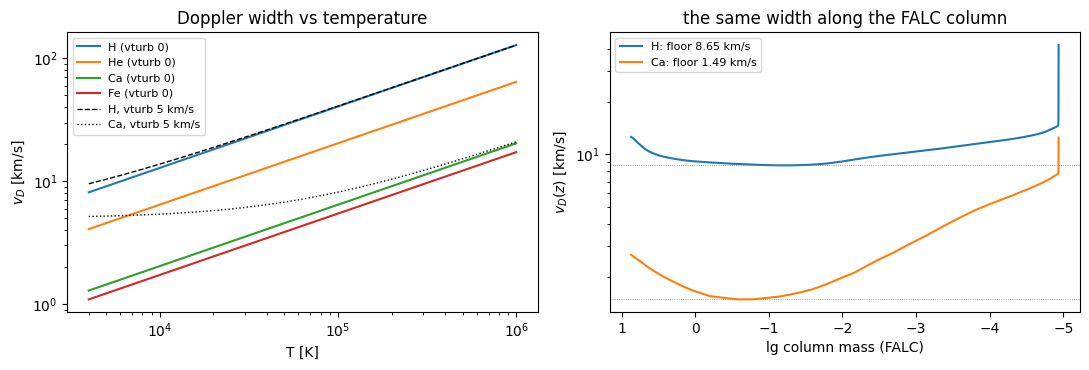

FALC: T 4500..100000 K, vturb 0.52..10.68 km/s
H alpha: ruler_from_atmosphere_ = 8.65 km/s (model floor at the temperature minimum; clip 1 km/s)
Ca II K: ruler_from_atmosphere_ = 1.49 km/s (model floor at the temperature minimum; clip 1 km/s)
clip demonstration, Ba II in a cold quiescent model: 1.00 km/s


In [2]:
rows = []
with (CFG._ROOT_DIR / "data" / "atmos" / "FAL" / "FALC_82.atmos").open() as f:
    for ln in f:
        parts = ln.split()
        if len(parts) == 5 and not ln.lstrip().startswith("*"):
            try:
                rows.append([float(p) for p in parts])
            except ValueError:
                continue
falc = np.array(rows)
assert falc.shape == (82, 5)
T_z, vt_z = falc[:, 1], falc[:, 4] * 1.0e5  # vturb column is km/s


def xi_line_kms_(mass, T, vturb):
    return np.sqrt(2.0 * CST.k_ * T / (mass * CST.mH_) + vturb * vturb) / 1.0e5


SPECIES = (("H", 1.008), ("He", 4.003), ("Ca", 40.08), ("Fe", 55.85))
T_grid = np.geomspace(4.0e3, 1.0e6, 200)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for nm, mass in SPECIES:
    axes[0].loglog(T_grid, xi_line_kms_(mass, T_grid, 0.0), label=f"{nm} (vturb 0)")
axes[0].loglog(T_grid, xi_line_kms_(1.008, T_grid, 5.0e5), "k--", lw=1.0, label="H, vturb 5 km/s")
axes[0].loglog(T_grid, xi_line_kms_(40.08, T_grid, 5.0e5), "k:", lw=1.0, label="Ca, vturb 5 km/s")
axes[0].set_xlabel("T [K]")
axes[0].set_ylabel(r"$v_D$ [km/s]")
axes[0].set_title("Doppler width vs temperature")
axes[0].legend(fontsize=8)

low = T_z <= 3.0e4  # below the transition region
for nm, mass in (("H", 1.008), ("Ca", 40.08)):
    xi_z = xi_line_kms_(mass, T_z, vt_z)
    axes[1].semilogy(falc[:, 0], xi_z, label=f"{nm}: floor {xi_z[low].min():.2f} km/s")
    axes[1].axhline(xi_z[low].min(), lw=0.6, ls=":", color="0.5")
axes[1].invert_xaxis()  # column mass decreases upward
axes[1].set_xlabel("lg column mass (FALC)")
axes[1].set_ylabel(r"$v_D(z)$ [km/s]")
axes[1].set_title("the same width along the FALC column")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

XI_FLOOR = {"H alpha": GlobalMesh.ruler_from_atmosphere_(T_z[low], vt_z[low], 1.008),
            "Ca II K": GlobalMesh.ruler_from_atmosphere_(T_z[low], vt_z[low], 40.08)}
print(f"FALC: T {T_z.min():.0f}..{T_z.max():.0f} K, vturb {vt_z.min() / 1e5:.2f}..{vt_z.max() / 1e5:.2f} km/s")
for nm, xi in XI_FLOOR.items():
    print(f"{nm}: ruler_from_atmosphere_ = {xi / 1e5:.2f} km/s (model floor at the temperature minimum; clip 1 km/s)")
print(f"clip demonstration, Ba II in a cold quiescent model: "
      f"{GlobalMesh.ruler_from_atmosphere_(4500.0, 0.0, 137.33) / 1e5:.2f} km/s")


## 2. Error vs ruler: the U-curve and its mass scaling

One fixed template (`make_full_line_mesh_(41, 2.5, 10.0)`), static case,
$J$ = the measured quiet-Sun atlas, ruler $\xi_{\rm ref}$ swept over two
decades. Every ruler value moves **both** knobs at once — core spacing
(~0.19 $\xi_{\rm ref}$ for this template) *and* wing extent
($\pm 10\,\xi_{\rm ref}$) — so the error is U-shaped:

- **ruler too small** → the window truncates the profile
  ($|w_\varphi - 1|$ blows up on the extent side);
- **ruler too large** → the core is undersampled (the narrow line's
  $\varphi$ falls between nodes).

The left panel plots the $J$-independent mesh metric $|w_\varphi - 1|$
against $\xi_{\rm ref}/v_D$: the two lines **collapse onto one curve**,
which is the measured proof that the ruler is a per-line quantity in
units of the line's own Doppler width — i.e. the $1/\sqrt{m}$ (plus
turbulence) scaling is the right normalization. The right panel shows the
$\bar J$ error in absolute km/s: the valleys sit at different rulers
purely because the masses differ.


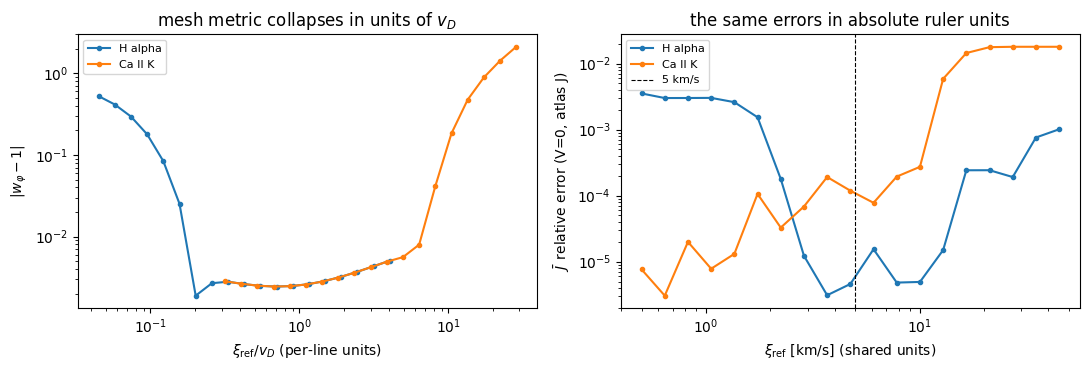

template 41/2.5/10, V=0, J = atlas:
--- H alpha (v_D 11.14 km/s) ---
  xi=  1.25 km/s (core dv  0.24, extent +-  12): |wphi-1| =  1.1e-01   Jbar err =  2.8e-03
  xi=  2.50 km/s (core dv  0.47, extent +-  25): |wphi-1| =  1.3e-03   Jbar err =  3.8e-05
  xi=  5.00 km/s (core dv  0.95, extent +-  50): |wphi-1| =  2.6e-03   Jbar err =  2.1e-05
  xi= 10.00 km/s (core dv  1.90, extent +- 100): |wphi-1| =  2.5e-03   Jbar err =  4.9e-06
  xi= 20.00 km/s (core dv  3.80, extent +- 200): |wphi-1| =  3.1e-03   Jbar err =  3.4e-05
  xi= 40.00 km/s (core dv  7.60, extent +- 400): |wphi-1| =  4.7e-03   Jbar err =  2.0e-03
--- Ca II K (v_D 1.58 km/s) ---
  xi=  1.25 km/s (core dv  0.24, extent +-  12): |wphi-1| =  2.4e-03   Jbar err =  7.5e-06
  xi=  2.50 km/s (core dv  0.47, extent +-  25): |wphi-1| =  2.9e-03   Jbar err =  2.6e-06
  xi=  5.00 km/s (core dv  0.95, extent +-  50): |wphi-1| =  4.3e-03   Jbar err =  1.1e-04
  xi= 10.00 km/s (core dv  1.90, extent +- 100): |wphi-1| =  7.8e-03   Jbar err 

In [3]:
q41 = MeshUtil.make_full_line_mesh_(41, 2.5, 10.0)
xi_grid = np.geomspace(0.5, 45.0, 19) * 1.0e5

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for name, (w0, dop, awl, aI) in LINES.items():
    vD = dop / w0 * CST.c_
    ew = np.empty(xi_grid.size)
    ej = np.empty(xi_grid.size)
    for i, xi in enumerate(xi_grid):
        ew[i], ej[i] = static_errors_(w0, dop, awl, aI, xi, q41)
    axes[0].loglog(xi_grid / vD, np.maximum(ew, 1e-12), "o-", ms=3, label=name)
    axes[1].loglog(xi_grid / 1e5, np.maximum(ej, 1e-12), "o-", ms=3, label=name)
axes[0].set_xlabel(r"$\xi_{\rm ref} / v_D$ (per-line units)")
axes[0].set_ylabel(r"$|w_\varphi - 1|$")
axes[0].set_title("mesh metric collapses in units of $v_D$")
axes[0].legend(fontsize=8)
axes[1].axvline(5.0, color="k", lw=0.8, ls="--", label="5 km/s")
axes[1].set_xlabel(r"$\xi_{\rm ref}$ [km/s] (shared units)")
axes[1].set_ylabel(r"$\bar J$ relative error (V=0, atlas J)")
axes[1].set_title("the same errors in absolute ruler units")
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

print("template 41/2.5/10, V=0, J = atlas:")
for name, (w0, dop, awl, aI) in LINES.items():
    print(f"--- {name} (v_D {dop / w0 * CST.c_ / 1e5:.2f} km/s) ---")
    for xi in (1.25e5, 2.5e5, 5.0e5, 10.0e5, 20.0e5, 40.0e5):
        ew, ej = static_errors_(w0, dop, awl, aI, xi, q41)
        print(f"  xi={xi / 1e5:6.2f} km/s (core dv {0.19 * xi / 1e5:5.2f}, extent +-{10 * xi / 1e5:4.0f}): "
              f"|wphi-1| = {ew:8.1e}   Jbar err = {ej:8.1e}")


The hydrogen valley is broad — anything from ~2.5 to ~20 km/s keeps
H$\alpha$ at or below a few 1e-5 — and **5 km/s sits mid-valley with a
factor ~2 margin on the truncation side and ~4 on the undersampling
side**: a safe default for a hydrogen-ruled axis. The same 5 km/s is
already marginal for Ca II K (1.1e-4) and 20 km/s is catastrophic for it
(1.7e-2, $|w_\varphi - 1| = 0.39$) while remaining perfectly fine for
H$\alpha$ — the shared-ruler failure is entirely a mass effect.


## 3. Naive mass scaling and its extent trap

Scale each line's ruler to its FALC floor and rebuild the two-line axis.
At $V = 0$ this is strictly better at identical cost — same 41 points per
window, same merged `Nspect`, and Ca II K improves ~5x. But the template
couples extent to the ruler ($\pm 10\,\xi$), so the scaled Ca II K window
now ends at $\pm 15$ km/s: a modest Doppler shift walks the core straight
out of it. The naive scaling fixes the core and breaks the coverage —
spacing and extent must be **decoupled** before this can be wired into
the generator.


[shared 5 km/s] merged Nspect = 82
  H alpha: xi =  5.00 km/s, extent +- 50.0 km/s, |wphi-1| =  2.6e-03, Jbar err =  2.1e-05
  Ca II K: xi =  5.00 km/s, extent +- 50.0 km/s, |wphi-1| =  4.3e-03, Jbar err =  1.1e-04
[scaled to the FALC floor] merged Nspect = 82
  H alpha: xi =  8.65 km/s, extent +- 86.5 km/s, |wphi-1| =  2.4e-03, Jbar err =  1.1e-05
  Ca II K: xi =  1.49 km/s, extent +- 14.9 km/s, |wphi-1| =  2.5e-03, Jbar err =  2.1e-05
Ca II K, xi= 5.00: err at V=20 km/s -> 4.4e-04, V=30 -> 1.7e-03
Ca II K, xi= 1.49: err at V=20 km/s -> 3.7e-02, V=30 -> 1.3e-01


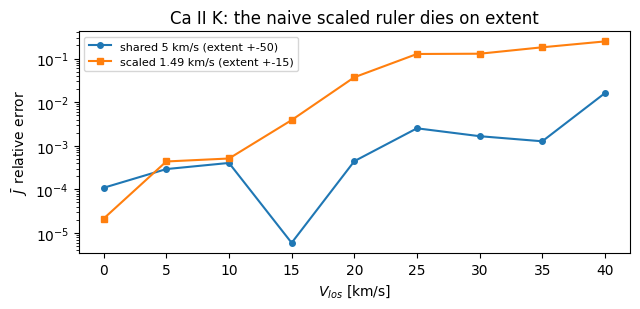

In [4]:
for label in ("shared 5 km/s", "scaled to the FALC floor"):
    def xi_of(nm, label=label):
        return 5.0e5 if label.startswith("shared") else XI_FLOOR[nm]

    meshes = [GlobalMesh.anchor_line_mesh_(q41, LINES[nm][0], xi_of(nm)) for nm in LINES]
    mesh = GlobalMesh.merge_meshes_(meshes)
    print(f"[{label}] merged Nspect = {mesh.wl.size}")
    for nm in LINES:
        w0, dop, awl, aI = LINES[nm]
        ew, ej = static_errors_(w0, dop, awl, aI, xi_of(nm), q41)
        print(f"  {nm}: xi = {xi_of(nm) / 1e5:5.2f} km/s, extent +-{10 * xi_of(nm) / 1e5:5.1f} km/s, "
              f"|wphi-1| = {ew:8.1e}, Jbar err = {ej:8.1e}")

w0, dop, awl, aI = LINES["Ca II K"]
V_scan = np.arange(0.0, 41.0, 5.0) * 1.0e5
fig, ax = plt.subplots(figsize=(6.5, 3.2))
for xi, lab, st in ((5.0e5, "shared 5 km/s (extent +-50)", "o-"),
                    (XI_FLOOR["Ca II K"], f"scaled {XI_FLOOR['Ca II K'] / 1e5:.2f} km/s (extent +-15)", "s-")):
    errs = [static_errors_(w0, dop, awl, aI, xi, q41, V)[1] for V in V_scan]
    ax.semilogy(V_scan / 1e5, np.maximum(errs, 1e-12), st, ms=4, label=lab)
    print(f"Ca II K, xi={xi / 1e5:5.2f}: err at V=20 km/s -> {errs[4]:.1e}, V=30 -> {errs[6]:.1e}")
ax.set_xlabel("$V_{los}$ [km/s]")
ax.set_ylabel(r"$\bar J$ relative error")
ax.set_title("Ca II K: the naive scaled ruler dies on extent")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


## 4. The decoupled recipe (follow-up, measured here)

The wired-in generator keeps `qcore`/`qwing` from the atom data files (the
RH convention), so extent stays the data file's responsibility for now —
this section measures what the follow-up decoupling would buy, to size
that decision. Give the generator two independent physical inputs per line
and derive the template parameters from them:

- **core spacing** from the line's own floor width: ruler
  $\xi_{\rm line}$, spacing target $\le \xi_{\rm line}/2$ in the core;
- **wing extent** in velocity units, set by damping-wing / velocity-band
  needs, independent of the species: `qwing = extent / xi_line`.

`nLambda` is then the smallest template that satisfies the spacing target.
For both benchmark lines that is **the same 41 points** as before —
reshaping the template (larger `qwing/qcore` ratio pushes more of the
log-spaced wing outward) buys per-line core resolution *and* a full
$\pm 100$ km/s extent at unchanged budget.


In [5]:
def decoupled_template_(xi_line, extent, spacing_frac=0.5, qcore=2.5):
    # smallest odd template whose core spacing (in q units) meets the target;
    # qwing carries the extent so the ruler only sets the core scale
    qwing = max(extent / xi_line, 2.0 * qcore + 1.0e-3)
    nLambda = 41
    while True:
        q = MeshUtil.make_full_line_mesh_(nLambda, qcore, qwing)
        if np.diff(q).min() <= spacing_frac or nLambda > 4001:
            return nLambda, q
        nLambda += 2


EXTENT = 100.0e5  # +-100 km/s coverage for every line, species-independent
for nm in LINES:
    w0, dop, awl, aI = LINES[nm]
    xi = XI_FLOOR[nm]
    nLambda, q = decoupled_template_(xi, EXTENT)
    ew0, ej0 = static_errors_(w0, dop, awl, aI, xi, q)
    _ew, ej50 = static_errors_(w0, dop, awl, aI, xi, q, 50.0e5)
    print(f"{nm}: xi = {xi / 1e5:.2f} km/s, qwing = {EXTENT / xi:.1f}, nLambda = {nLambda}, "
          f"core dv = {np.diff(q).min() * xi / 1e5:.2f} km/s")
    print(f"   V=0 : |wphi-1| = {ew0:8.1e}, Jbar err = {ej0:8.1e}")
    print(f"   V=50: Jbar err = {ej50:8.1e}   (log wing: adequate statically; the dynamic band will densify it)")


H alpha: xi = 8.65 km/s, qwing = 11.6, nLambda = 41, core dv = 1.60 km/s
   V=0 : |wphi-1| =  3.0e-03, Jbar err =  9.4e-07
   V=50: Jbar err =  8.3e-04   (log wing: adequate statically; the dynamic band will densify it)
Ca II K: xi = 1.49 km/s, qwing = 67.1, nLambda = 41, core dv = 0.12 km/s
   V=0 : |wphi-1| =  1.4e-02, Jbar err =  6.7e-05
   V=50: Jbar err =  2.5e-03   (log wing: adequate statically; the dynamic band will densify it)


## Summary

1. **$T_{\rm char}$ / $\xi_{\rm turb,char}$ come from the atmosphere, not
   the user**: the mesh must resolve the smallest width the line exhibits,
   which is $v_D(z)$ at the temperature minimum of the model (FALC:
   8.65 km/s for hydrogen, 1.49 km/s for Ca II) — optionally restricted to
   the depths where the species exists, with a user override kept only as
   an expert knob.
2. **Yes, the ruler scales with the mass** — the $J$-independent mesh
   metric $|w_\varphi - 1|$ collapses onto a single curve when the ruler
   is expressed in units of each line's $v_D = \sqrt{2kT/m +
   \xi_{\rm turb}^2}$. A shared ruler is a hidden per-species accuracy
   lottery: 20 km/s is fine for H$\alpha$ and catastrophic for Ca II K on
   the same axis.
3. **5 km/s is a safe default for a hydrogen-ruled axis** — mid-valley,
   with a factor ~2 margin against truncation and ~4 against
   undersampling for the 41/2.5/10 template. It is *not* a safe shared
   default for heavy species.
4. **Wired in now vs deferred**: the per-species ruler is
   `GlobalMesh.ruler_from_atmosphere_(T, vturb, mass, floor=1 km/s)`;
   `qcore`/`qwing` keep coming from the atom data files, which therefore
   retain responsibility for extent (a scaled-down ruler shrinks
   $\pm q_{\rm wing}\,\xi_{\rm line}$ — data files of narrow-species
   lines must carry correspondingly larger `qwing`, as RH atom files do).
   The extent decoupling measured in section 4 (`qwing = extent /
   xi_line` at unchanged `nLambda`) is tracked as a follow-up issue, and
   the dynamic (velocity-band) merge then densifies the log wing where
   shifted cores actually land.
